# Diamond Data Analysis

This notebook analyzes the diamond dataset to understand various characteristics and patterns in diamond properties.

In [27]:
# Import required libraries
import pandas as pd

import seaborn as sns
import matplotlib.pylab as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,Ridge
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import KFold, cross_val_score

### 1. Data Selection
Description of data inclusive

In [28]:
#1. Data Selection
#Import data
data = pd.read_csv("/content/diamonds.csv")
print(data.head()) #see first 5 rows of data

#This is to confirm whether the file used is correct

   carat      cut color clarity  depth  table  price     x     y     z
0   0.23    Ideal     E     SI2   61.5   55.0    326  3.95  3.98  2.43
1   0.21  Premium     E     SI1   59.8   61.0    326  3.89  3.84  2.31
2   0.23     Good     E     VS1   56.9   65.0    327  4.05  4.07  2.31
3   0.29  Premium     I     VS2   62.4   58.0    334  4.20  4.23  2.63
4   0.31     Good     J     SI2   63.3   58.0    335  4.34  4.35  2.75


In [29]:
print(data.tail()) #see last 5 rows of data

       carat        cut color clarity  depth  table  price     x     y     z
49995   0.72      Ideal     D     SI1   60.8   57.0   2757  5.75  5.76  3.50
49996   0.72       Good     D     SI1   63.1   55.0   2757  5.69  5.75  3.61
49997   0.70  Very Good     D     SI1   62.8   60.0   2757  5.66  5.68  3.56
49998   0.86    Premium     H     SI2   61.0   58.0   2757  6.15  6.12  3.74
49999   0.75      Ideal     D     SI2   62.2   55.0   2757  5.83  5.87  3.64


In [30]:
#Further exploration of data
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    50000 non-null  float64
 1   cut      50000 non-null  object 
 2   color    50000 non-null  object 
 3   clarity  50000 non-null  object 
 4   depth    50000 non-null  float64
 5   table    50000 non-null  float64
 6   price    50000 non-null  int64  
 7   x        50000 non-null  float64
 8   y        50000 non-null  float64
 9   z        50000 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 3.8+ MB
None


In [31]:
print(data.cut.value_counts())
print(data.color.value_counts())
print(data.clarity.value_counts())

cut
Ideal        19938
Premium      12806
Very Good    11204
Good          4557
Fair          1495
Name: count, dtype: int64
color
G    10452
E     9085
F     8864
H     7711
D     6224
I     5058
J     2606
Name: count, dtype: int64
clarity
SI1     12115
VS2     11404
SI2      8519
VS1      7579
VVS2     4694
VVS1     3369
IF       1632
I1        688
Name: count, dtype: int64


In [32]:
print(data.duplicated().sum()) #check for duplicates

126


In [33]:
print(data.isnull().sum()) #check for any NaN values

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64


In [34]:
print(data[data.y == 0])

       carat        cut color clarity  depth  table  price    x    y    z
11038   1.00  Very Good     H     VS2   63.3   53.0   5139  0.0  0.0  0.0
14731   1.14       Fair     G     VS1   57.5   67.0   6381  0.0  0.0  0.0
22721   1.56      Ideal     G     VS2   62.2   54.0  12800  0.0  0.0  0.0
24336   1.20    Premium     D    VVS1   62.1   59.0  15686  0.0  0.0  0.0
25439   2.25    Premium     H     SI2   62.8   59.0  18034  0.0  0.0  0.0
45910   0.71       Good     F     SI2   64.1   60.0   2130  0.0  0.0  0.0


There are data with x y and z having 0 values, which do not make sense.
we will address them later.

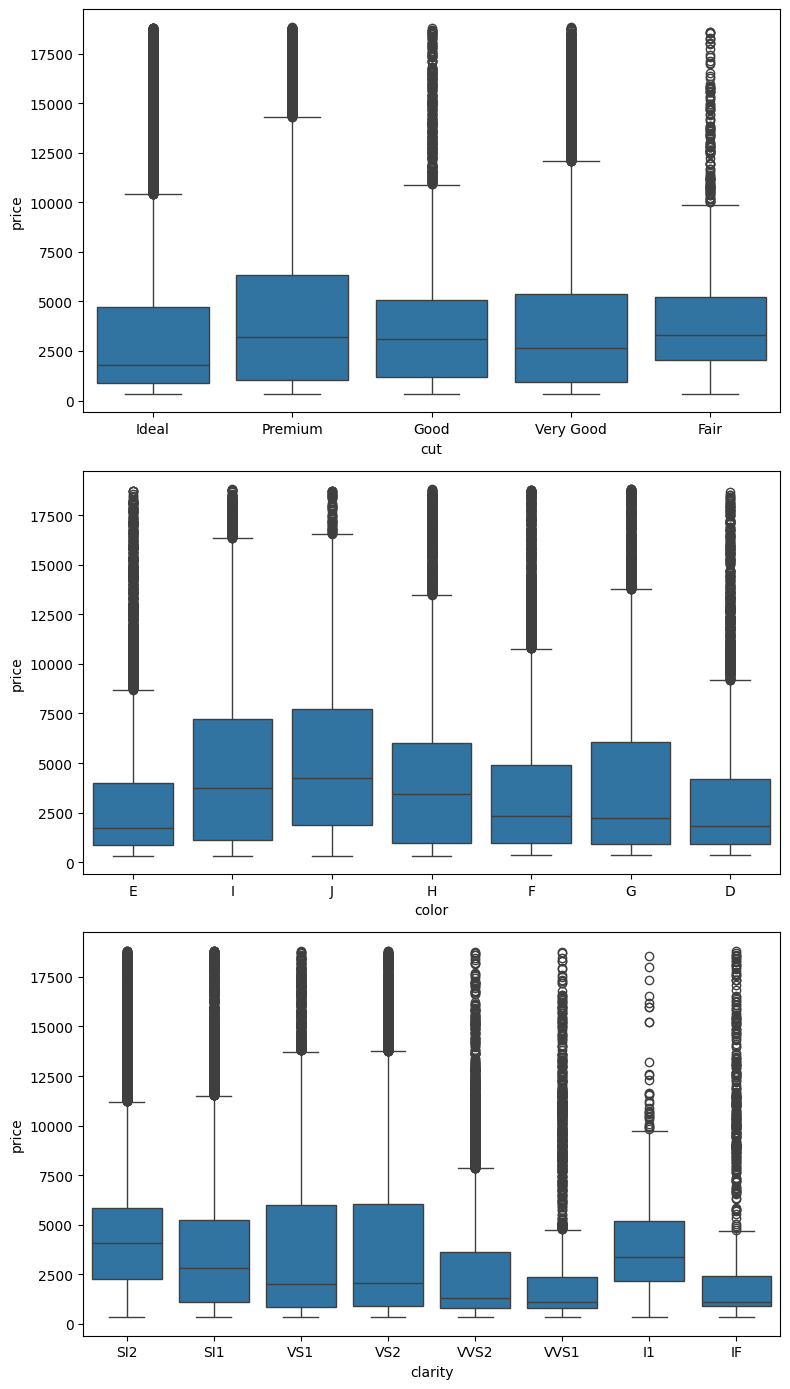

In [35]:
plt.figure(figsize=(8, 14))
plt.subplot(3,1,1)
sns.boxplot(x = 'cut', y = 'price', data = data)
plt.subplot(3,1,2)
sns.boxplot(x = 'color', y = 'price', data = data)
plt.subplot(3,1,3)
sns.boxplot(x = 'clarity', y = 'price', data = data)
plt.tight_layout()
plt.show()

From the boxplots, we observe that cut, color, and clarity do not show clear relationships wrt diamond price. For example, Fair cut and lower color grades (I, J) sometimes show higher median prices than their “better” counterparts. Similarly, diamonds with low clarity (I1) can still lead to high prices. This suggests that these categorical features interact strongly with other numerical attributes, especially carat, which has a dominant effect on price. Hence, these categorical variables will be converted to numerical form by using Label Encoding before the regression analysis.

In [36]:
numerical_columns = [key for key, value in data.dtypes.items()  if value!='O']
corr_matrix = data[numerical_columns].corr()
print(corr_matrix['price'].sort_values(ascending=False))

price    1.000000
carat    0.921804
x        0.884919
y        0.864393
z        0.860963
table    0.129848
depth   -0.012731
Name: price, dtype: float64


From the results, carat has the strongest positive correlation to price, where carat increases, price increases dimensions x y and z also have strong positive correlation to price, since bigger stones, means greater price. On the other hand, depth and table do not determine the price value due to their low correlation

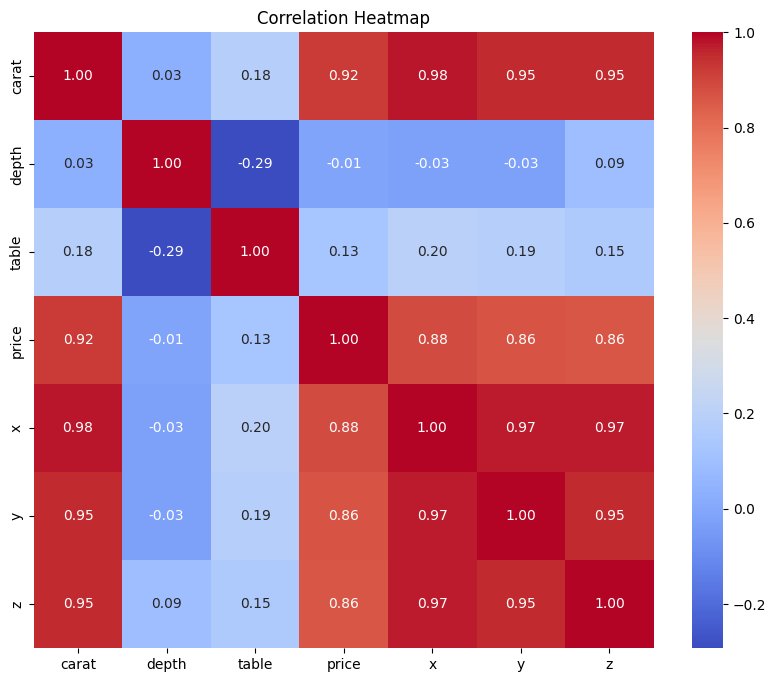

In [37]:
# Plot heatmap
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

This result shows that there is multicollinearity.
Since carat, x y and z are highly correlated with each other as well as with the price.

### 2. Data Preprocessing

In [38]:
#2. Data Preprocessing
newdata = data.copy() #copy of new data
print(newdata.shape) #check data rowss and columns

(50000, 10)


There are 50000 rows and 10 columns
However, we know that there are 126 duplicates in the dataset

In [39]:
#Remove duplicates
newdata = newdata.drop_duplicates()
print(newdata.shape)

(49874, 10)


Now there are 49874 rows and 10 columns, which is correct
Because 50000-126=49874

In [40]:
#Remove zero values
#We know that zero values are present hence we want to remove them
newdata = newdata[newdata.z != 0].reset_index(drop=True)
print(newdata.describe()[['x','y','z']].loc['min'])
#see minimum values of the diamond dimensions x y and z, to check whether the zero values are removed
print(newdata.shape)


x    3.73
y    3.68
z    1.07
Name: min, dtype: float64
(49857, 10)


After removing the data with zero values, we have now 49857 rows

In [41]:
#Feature Encoding (Label Encoding on categorical variables)
label_cut = LabelEncoder()
label_color = LabelEncoder()
label_clarity = LabelEncoder()


newdata['cut'] = label_cut.fit_transform(newdata['cut'])
newdata['color'] = label_color.fit_transform(newdata['color'])
newdata['clarity'] = label_clarity.fit_transform(newdata['clarity'])
print(newdata.head())

   carat  cut  color  clarity  depth  table  price     x     y     z
0   0.23    2      1        3   61.5   55.0    326  3.95  3.98  2.43
1   0.21    3      1        2   59.8   61.0    326  3.89  3.84  2.31
2   0.23    1      1        4   56.9   65.0    327  4.05  4.07  2.31
3   0.29    3      5        5   62.4   58.0    334  4.20  4.23  2.63
4   0.31    1      6        3   63.3   58.0    335  4.34  4.35  2.75


Each of the unique strings will be assigned numerical values accordingly starting from 0.
As you can see instead of strings being used for cut color and clarity, there are now different unique numbers


In [42]:
#Split data into training and testing
X = newdata.drop(['price'], axis=1) #all variables are treated as predictors except for price
y = newdata['price'] #assign y as the target variable

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=66)
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

New dataset of 49857 rows is split into 80% training and 20% test.
Standardscaler transform the features so that mean = 0 and SD = 1.

### 3. Model Training & Evaluation

In [43]:
#Implementation of Kfold for Cross-Validation (CV)
kf = KFold(n_splits=5, shuffle=True, random_state=66)

The new dataset is randomly shuffled and split into 5 parts.
Each iteration, 4 folds are used to train, 1 fold for validation.
Random_state is to set a fixed seed for reproducibility.

In [44]:
#Linear Regression
clf_lr = LinearRegression()
clf_lr.fit(X_train , y_train) #fit the training data into the model
cv_scores_lr = cross_val_score(clf_lr, X_train, y_train, cv=kf, scoring='r2')
#by making use of the kFold, the model runs 5-fold CV on the training data
#where it will calculate the R^2 value of each fold
y_pred = clf_lr.predict(X_test)
#trained model is used to predict diamond prices based on the test set
print('')
print('####### Linear Regression #######')
print('Score : %.4f' % clf_lr.score(X_test, y_test))
print(cv_scores_lr)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('')
print('MSE: %0.2f ' % mse)
print('R2:  %0.2f ' % r2)


####### Linear Regression #######
Score : 0.8839
[0.88473845 0.88604625 0.88214273 0.88289883 0.88942807]

MSE: 1883357.03 
R2:  0.88 


Here, we obtain the R² and MSE values of Linear Regression

In [45]:
#Ridge Regression
clf_rr = Ridge(alpha=1)     # ridge regression

clf_rr.fit(X_train , y_train)
cv_scores_rr = cross_val_score(clf_rr, X_train, y_train, cv=kf, scoring='r2')
#by making use of the kFold, the model runs 5-fold CV on the training data
#where it will calculate the R² value of each fold
y_pred = clf_rr.predict(X_test)
#trained model is used to predict diamond prices based on the test set
print('')
print('###### Ridge Regression ######')
print('Score : %.4f' % clf_rr.score(X_test, y_test))
print(cv_scores_rr)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('')
print('MSE: %0.2f ' % mse)
print('R2:  %0.2f ' % r2)


###### Ridge Regression ######
Score : 0.8839
[0.88473864 0.88606298 0.88215211 0.88289719 0.88942868]

MSE: 1883527.38 
R2:  0.88 


Here, we obtain the R² and MSE values of Ridge Regression.

### 4. Analysis and Comparison

#### Compare the models using MSE and R² scores

Although the dataset exhibits multicollinearity, particularly among the carat, x, y, and z features as shown earlier.

Both Linear Regression and Ridge Regression produced nearly identical R² and MSE values.

This is because the dataset is large and clean after removing duplicate values and zero values. This causes the  coefficient estimation to be stabilized even in the presence of correlated predictors.

Even though RR introduces an L2 penalty to shrink correlated coefficients and improve robustness, the effect is minimal here since the LR model was already well-conditioned.

#### Analyse cases where Linear Regression ovefits and where Ridge Regression helps prevent overfitting

In [46]:
#Analyzing whether Linear Regression overfits
print("##### Checking whether LR overfits #####")
print("Train R²:", clf_lr.score(X_train, y_train))
print("Test R²:", clf_lr.score(X_test, y_test))

##### Checking whether LR overfits #####
Train R²: 0.885583041844302
Test R²: 0.8839147986417293


From the results:
On the training data, the Linear Regression model explains 88.56% of the variance in price
On the test data, the Linear Regression model explains 88.39% of the variance.

Since Train R² is greater than Test R², overfitting does exist in the LR model, meaning that the model fits training data better as compared to the test data

The small difference between the two values indicates mild overfitting,
However, the gap is very small (≈ 0.002), suggesting that the model still generalizes well overall.

In the case of Ridge Regression, it works by adding a L2 penalty that shrinks the coefficients slightly. Supposedly, to make the model less sensitive to small fluctuations or noise that exist in the training data.



### 5. Improving Model Performance

#### 5.1 Experiment with different alpha values in Ridge Regression and observe their effects

In [47]:
#5. Improving Model Performance
#Analyzing whether Ridge Regression helps to prevent overfitting
print("##### Checking Ridge Regression with different alpha values #####")
for a in [0.1, 1, 10, 100]:
    clf_rr = Ridge(alpha=a)
    clf_rr.fit(X_train, y_train)
    print(f"alpha={a}, Train R²={clf_rr.score(X_train, y_train):.4f}, Test R²={clf_rr.score(X_test, y_test):.4f}")

##### Checking Ridge Regression with different alpha values #####
alpha=0.1, Train R²=0.8856, Test R²=0.8839
alpha=1, Train R²=0.8856, Test R²=0.8839
alpha=10, Train R²=0.8856, Test R²=0.8838
alpha=100, Train R²=0.8853, Test R²=0.8844


With the increasing alpha values in Ridge Regression. The Train R² value drops slightly, while the Test R² value increase slightly.

This means that Ridge Regression helps to prevent overfitting by shrinking coefficients, by making sure that the train R² value and Test R² value are similar with increasing alpha
which helps to improve generalization.

#### Discuss practical applications where each model would be more suitable

In this project, both LR and RR have almost identical predictive performance (R² ≈ 0.884).
This suggests that the dataset is large and well-conditioned (after removing duplicates and zero values), which led to RR’s regularization penalty having minimal effect.

Therefore, LR would be more suitable for this specific problem, as it offers simplicity and interpretability without sacrificing accuracy.

However, if the same dataset had fewer samples, more noise, or stronger feature correlations (e.g., additional redundant measurements of diamond dimensions), RR would be preferred because it can stabilize coefficients and improve generalization.

For Practical Applications examples:
Linear Regression is most suitable for large, clean datasets with low noise, where model interpretability is important. For example, it is used in business forecasting to predict sales or pricing trends, where understanding how each factor (e.g., carat, clarity) affects price is most essential.

Whereas, Ridge Regression is more suitable when predictors are highly correlated or when overfitting is a concern. The L2 regularization term (penalty) in Ridge Regression helps to stabilize the model coefficients by shrinking them toward zero, making it ideal for medical or financial applications where many correlated variables are used for prediction.

In this project, both models performed similarly because the dataset was large and clean, but RR would be more beneficial in smaller, noisier, or more complex datasets.